Online Retail (UCI) — транзакции британского интернет-магазина подарков с 01.12.2010 по 09.12.2011, покупатели в основном оптовые.

Товар: **85099B — JUMBO BAG RED RETROSPOT** (на занятии разбирали 85123A, его не берём)

Функции анализа вынесены в `ts_utils.py`, в ноутбуке в основном их вызовы и интерпретация результатов

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

import ts_utils as tu

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)

DATA_PATH = 'Online Retail.xlsx'
STOCK_CODE = '85099B'

## Шаг 1. Данные и формирование временного ряда

### 1.1 Структура датасета

In [29]:
df = tu.load_data(DATA_PATH)   
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [31]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [32]:
print('строк-отмен (InvoiceNo начинается с C):', df['InvoiceNo'].str.startswith('C').sum())
print('строк с Quantity < 0:', (df['Quantity'] < 0).sum())
print('строк с UnitPrice <= 0:', (df['UnitPrice'] <= 0).sum())
print('доля пропусков CustomerID:', round(df['CustomerID'].isna().mean(), 3))
df[df['UnitPrice'] < 0]

строк-отмен (InvoiceNo начинается с C): 9288
строк с Quantity < 0: 10624
строк с UnitPrice <= 0: 2517
доля пропусков CustomerID: 0.249


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Что видно по структуре:
- 541 909 строк, 8 полей, одна строка = одна позиция в чеке.
- `Quantity` бывает отрицательным — это отмены и возвраты, у них номер чека начинается с «C».
- `UnitPrice` бывает нулевой и даже отрицательной (служебные записи вроде «Adjust bad debt»), т.е. в данных есть не только продажи.
- `CustomerID` пропущен примерно у четверти строк. Для ряда продаж это не страшно — покупка всё равно была.

Для построения ряда нужны:
- `StockCode` — отбор товара;
- `InvoiceDate` — дата (время отбрасываем, берём день);
- `Quantity` — показатель продаж;
- вспомогательные: `InvoiceNo` (отличить отмены), `UnitPrice` (отсечь служебные строки), `CustomerID` (понять, какой именно заказ был отменён).

### 1.2 Выбор товара

In [33]:
ok = ~df['InvoiceNo'].str.startswith('C') & (df['Quantity'] > 0) & (df['UnitPrice'] > 0)
tmp = df[ok].assign(day=df.loc[ok, 'InvoiceDate'].dt.normalize())
top = (tmp.groupby('StockCode')
          .agg(описание=('Description', 'first'),
               чеков=('InvoiceNo', 'nunique'),
               штук=('Quantity', 'sum'),
               дней_с_продажами=('day', 'nunique'))
          .sort_values('чеков', ascending=False))
print('всего дней с продажами в датасете:', tmp['day'].nunique())
top.head(10)

всего дней с продажами в датасете: 305


,описание,чеков,штук,дней_с_продажами
StockCode,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2198,37660,305
85099B,JUMBO BAG RED RETROSPOT,2089,48474,300
22423,REGENCY CAKESTAND 3 TIER,1988,13879,301
47566,PARTY BUNTING,1685,18295,294
20725,LUNCH BAG RED RETROSPOT,1565,19553,298
84879,ASSORTED COLOUR BIRD ORNAMENT,1455,36461,300
22197,SMALL POPCORN HOLDER,1392,56921,294
22720,SET OF 3 CAKE TINS PANTRY DESIGN,1385,7493,262
21212,PACK OF 72 RETROSPOT CAKE CASES,1320,36419,298


Лидер по числу чеков — 85123A, но его разбирали на занятии. Беру следующий — **85099B JUMBO BAG RED RETROSPOT** (большая хозяйственная сумка).
Он продаётся почти каждый рабочий день (300 дней из 305), так что ряд получится без длинных «дыр», и при этом у него много крупных оптовых заказов — есть что анализировать в плане выбросов.

**Показатель продаж — количество проданных штук (`Quantity`).** Выручку не беру: цена у товара зависит от покупателя (видно ниже — 1.65–1.79 при крупном опте, 2.08 обычная, 4.13 для покупателей без ID), и в выручке смешались бы спрос и ценовая политика. Для прогноза спроса количество честнее.

In [34]:
df.loc[df['StockCode'] == STOCK_CODE, 'UnitPrice'].value_counts().head(8)

UnitPrice
2.08    1114
4.13     427
1.95     327
1.79     146
1.65      72
4.21      42
1.74      12
2.46       8
Name: count, dtype: int64


Функция `prepare_product`:
- строки-отмены сами по себе в продажи не идут;
- если отмена совпадает с заказом того же клиента на то же количество в пределах суток — заказ фактически не состоялся (клиент исправил ошибку), удаляю и его. Это важно: такие заказы крупные (100–300 шт.) и без удаления дали бы ложные пики;
- частичные возвраты (обычно 1–10 шт., иногда через несколько недель) не трогаю: продажа была, а вычитать возврат в день возврата — значит рисовать искусственные провалы;
- строки с ценой 0 удаляю: у товара их 3, все без клиента — это служебные корректировки, а не продажи;
- строки без `CustomerID` оставляю — это обычные продажи незарегистрированным покупателям.

In [37]:
sales, report, cancelled = tu.prepare_product(df, STOCK_CODE)
pd.Series(report)

строк по товару                       2159
строк-отмен (C...)                      44
штук в отменах                        1115
строк с ценой <= 0                       3
строк с Quantity <= 0 (не отмены)        0
строк без CustomerID                   497
удалено отменённых заказов               6
штук в удалённых заказах               741
строк продаж после очистки            2106
штук продано после очистки           47733
dtype: int64

In [38]:
cancelled

,заказ,дата заказа,отмена,дата отмены,клиент,количество
0,540275,2011-01-06 12:11:00,C540417,2011-01-07 10:56:00,13680.0,100
1,560491,2011-07-19 10:51:00,C560540,2011-07-19 12:26:00,12415.0,1
2,569740,2011-10-06 10:52:00,C569743,2011-10-06 10:57:00,15769.0,140
3,570522,2011-10-11 10:46:00,C570552,2011-10-11 11:01:00,16029.0,300
4,572326,2011-10-24 09:55:00,C572334,2011-10-24 10:25:00,14607.0,100
5,575220,2011-11-09 11:19:00,C575224,2011-11-09 11:41:00,17511.0,100


Удалено 6 отменённых заказов на 741 шт., остальные ~370 шт. в отменах — мелкие возвраты. На фоне ~48 тыс. проданных штук это немного, но четыре из этих заказов пришлись на октябрь–ноябрь и заметно завысили бы отдельные дни.

### 1.4 Рабочий календарь магазина

Прежде чем строить дневной ряд, надо понять, в какие дни магазин вообще работал. «Нет продаж товара в день X» может значить две разные вещи:
1. магазин работал, но этот товар никто не купил — это **реальный ноль**;
2. магазин был закрыт — **наблюдения нет**, ставить 0 нельзя.

Рабочим считаю день, в который была хотя бы одна транзакция по любому товару.

In [40]:
trading_days = tu.get_trading_days(df)
print('рабочих дней:', len(trading_days))
pd.Series(trading_days.dayofweek).map(dict(enumerate(tu.WEEKDAYS_RU))).value_counts()

рабочих дней: 305


InvoiceDate
Ср    53
Чт    53
Вт    52
Пт    50
Вс    50
Пн    47
Name: count, dtype: int64

Ни одной субботы — по субботам магазин не работает в принципе. Ещё проверю последний день: датасет заканчивается 09.12.2011.

In [41]:
last_time = df.groupby(df['InvoiceDate'].dt.normalize())['InvoiceDate'].max()
hours = (last_time - last_time.dt.normalize()).dt.total_seconds() / 3600
print('медиана времени последнего чека за день, ч:', round(hours.median(), 1))
hours.tail(3)

медиана времени последнего чека за день, ч: 17.4


InvoiceDate
2011-12-07    18.633333
2011-12-08    20.016667
2011-12-09    12.833333
Name: InvoiceDate, dtype: float64

Обычно последний чек около 17:30, а 09.12.2011 данные обрываются в 12:50 — день неполный (выгрузку просто сделали в середине дня). Если его оставить, получится ложный провал в конце ряда, поэтому ряд беру до **08.12.2011** включительно.

### 1.5 Агрегация по дням, неделям и месяцам

In [42]:
daily_cal = tu.make_daily(sales, trading_days)[:'2011-12-08']   # календарные дни, NaN = магазин закрыт
weekly_raw = tu.aggregate(daily_cal, 'W')    # недели пн-вс
monthly_raw = tu.aggregate(daily_cal, 'M')

print('дней:', len(daily_cal), '| недель:', len(weekly_raw), '| месяцев:', len(monthly_raw))
monthly_raw

дней: 373 | недель: 54 | месяцев: 13


,qty,trading_days,complete
period_start,,,
2010-12-01,2151.0,20,True
2011-01-01,2647.0,24,True
2011-02-01,3080.0,24,True
2011-03-01,5280.0,27,True
2011-04-01,2456.0,21,True
2011-05-01,3621.0,25,True
2011-06-01,3681.0,26,True
2011-07-01,3128.0,26,True
2011-08-01,5502.0,26,True


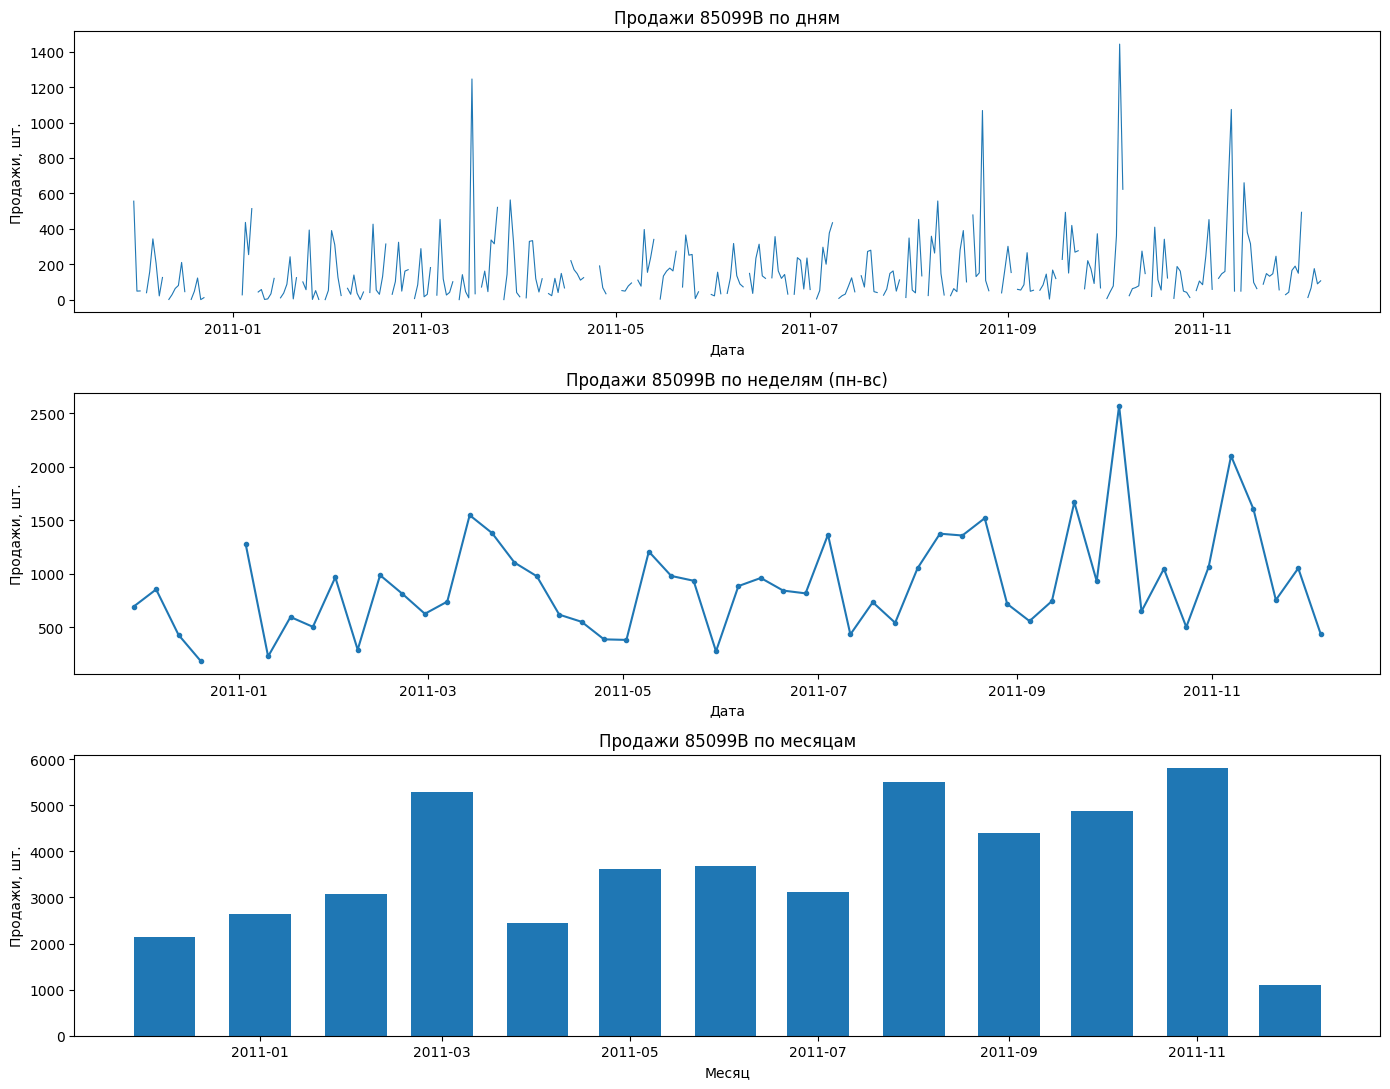

In [43]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
tu.plot_series(daily_cal, 'Продажи 85099B по дням', ax=axes[0], lw=0.8)
tu.plot_series(weekly_raw['qty'], 'Продажи 85099B по неделям (пн-вс)', ax=axes[1], marker='o', ms=3)
axes[2].bar(monthly_raw.index, monthly_raw['qty'], width=20)
axes[2].set_title('Продажи 85099B по месяцам')
axes[2].set_xlabel('Месяц')
axes[2].set_ylabel('Продажи, шт.')
plt.tight_layout()
plt.show()

Первое впечатление:
- дневной ряд очень шумный, на фоне типичных десятков–пары сотен штук есть отдельные дни по 1000+ шт.;
- на недельном и месячном уровне виден рост продаж в течение 2011 года;
- провалы в конце декабря 2010 и в декабре 2011 на недельном/месячном графике — это не падение спроса, а закрытие на Рождество и обрезанный конец данных. Разбираю ниже.

## Шаг 2. Качество данных

### 2.1 Ряд до обработки

Для сравнения — дневные продажи товара «как есть» (с отменами, т.е. Quantity просто просуммирован по дням) и после очистки.

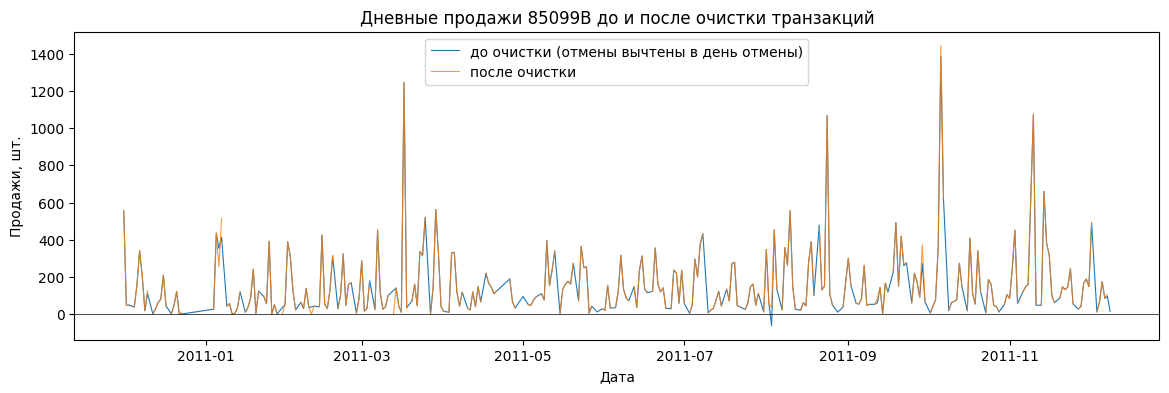

дней с отрицательной суммой до очистки: 2


In [44]:
p_all = df[df['StockCode'] == STOCK_CODE]
raw_net = p_all.groupby(p_all['InvoiceDate'].dt.normalize())['Quantity'].sum()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(raw_net.index, raw_net, lw=0.8, label='до очистки (отмены вычтены в день отмены)')
ax.plot(daily_cal.index, daily_cal, lw=0.8, alpha=0.8, label='после очистки')
ax.axhline(0, color='black', lw=0.5)
ax.set_title('Дневные продажи 85099B до и после очистки транзакций')
ax.set_xlabel('Дата')
ax.set_ylabel('Продажи, шт.')
ax.legend()
plt.show()

print('дней с отрицательной суммой до очистки:', (raw_net < 0).sum())

В «сыром» варианте отмены дают провалы (вплоть до отрицательных значений), а отменённые заказы — лишние пики. После очистки ряд неотрицательный.

### 2.2 Пропуски

In [45]:
uk_holidays = {
    '2010-12-24': 'рождественские каникулы',
    '2010-12-26': 'рождественские каникулы',
    '2010-12-27': 'Рождество (перенос с субботы)',
    '2010-12-28': 'Boxing Day (перенос)',
    '2010-12-29': 'рождественские каникулы',
    '2010-12-30': 'рождественские каникулы',
    '2010-12-31': 'рождественские каникулы',
    '2011-01-02': 'рождественские каникулы',
    '2011-01-03': 'Новый год (перенос с субботы)',
    '2011-04-22': 'Страстная пятница',
    '2011-04-24': 'Пасха',
    '2011-04-25': 'Пасхальный понедельник',
    '2011-04-29': 'королевская свадьба (доп. выходной)',
    '2011-05-02': 'майский банковский выходной',
    '2011-05-30': 'весенний банковский выходной',
    '2011-08-29': 'летний банковский выходной',
}
miss = tu.missing_report(daily_cal, uk_holidays)
print('календарных дней без наблюдений:', len(miss), 'из', len(daily_cal))
print(miss['день недели'].value_counts().to_dict())
miss[miss['день недели'] != 'Сб']

календарных дней без наблюдений: 69 из 373
{'Сб': 53, 'Пн': 6, 'Пт': 4, 'Вс': 3, 'Вт': 1, 'Ср': 1, 'Чт': 1}


,дата,день недели,причина
3,2010-12-24,Пт,рождественские каникулы
5,2010-12-26,Вс,рождественские каникулы
6,2010-12-27,Пн,Рождество (перенос с субботы)
7,2010-12-28,Вт,Boxing Day (перенос)
8,2010-12-29,Ср,рождественские каникулы
9,2010-12-30,Чт,рождественские каникулы
10,2010-12-31,Пт,рождественские каникулы
12,2011-01-02,Вс,рождественские каникулы
13,2011-01-03,Пн,Новый год (перенос с субботы)
29,2011-04-22,Пт,Страстная пятница


Все дни без наблюдений объяснимы: 53 субботы (магазин не работает) и 16 праздничных/выходных дней, из них 9 — закрытие с 24.12.2010 по 03.01.2011. Причин «неизвестно» нет, т.е. **потерянных данных нет** — это календарь магазина.

Теперь дни, когда магазин работал, а товар не продали:

In [46]:
zeros = daily_cal[daily_cal == 0]
print('рабочих дней с нулевыми продажами товара:', len(zeros))
pd.DataFrame({'день недели': [tu.WEEKDAYS_RU[d.dayofweek] for d in zeros.index]}, index=zeros.index.date)

рабочих дней с нулевыми продажами товара: 5


,день недели
2010-12-22,Ср
2011-01-30,Вс
2011-02-10,Чт
2011-03-13,Вс
2011-03-27,Вс


Таких дней всего 5: три воскресенья (по воскресеньям заказов вообще мало) и два будних дня, включая 22.12.2010 перед закрытием на Рождество. Это настоящие нулевые продажи, они остаются нулями.

Неполные периоды в недельном и месячном рядах:

In [47]:
weekly_raw[(~weekly_raw['complete']) | weekly_raw['qty'].isna() | (weekly_raw['trading_days'] < 6)]

,qty,trading_days,complete
period_start,,,
2010-11-29,692.0,4,False
2010-12-20,180.0,4,True
2010-12-27,NaN,0,True
2011-01-03,1274.0,5,True
2011-04-18,549.0,4,True
2011-04-25,385.0,4,True
2011-05-02,380.0,5,True
2011-05-30,273.0,5,True
2011-08-29,717.0,5,True


**Как обрабатываю:**

- *Дневной ряд.* Субботы — не пропуски, а нерабочие дни, поэтому дальше работаю на регулярной сетке из 6 дней в неделю (пн–пт + вс). На ней остаются 16 праздничных дней. Нулями их заполнять нельзя — магазин был закрыт, спрос в эти дни не наблюдался. В описательных статистиках они просто исключаются, а для STL и тестов стационарности (им нужен ряд без пропусков на регулярной сетке) заполняю их **линейной интерполяцией**. Это ~5% точек, на графике они отмечены.
- *Недельный ряд.* Первая (01–05.12.2010, начало данных в среду) и последняя (05–08.12.2011) недели неполные — убираю, иначе на краях будут искусственные провалы. Неделя 27.12–02.01 — магазин закрыт целиком, значение интерполирую. Недели с праздниками (4–5 рабочих дней вместо 6) оставляю как есть: продажи там действительно были ниже, но при интерпретации надо помнить, что отчасти из-за календаря.
- *Месячный ряд.* Декабрь 2011 — только 7 рабочих дней, убираю. Остаётся 12 полных месяцев (дек 2010 – ноя 2011). Декабрь 2010 считаю полным: закрытие на Рождество — нормальная часть декабря.

In [48]:
daily = tu.to_six_day_grid(daily_cal)      # 6-дневная сетка, NaN = праздник
daily_f = tu.fill_gaps(daily)              # для STL и тестов

weekly = weekly_raw.loc[weekly_raw['complete'], 'qty']
weekly_f = tu.fill_gaps(weekly)

monthly = monthly_raw.loc[monthly_raw['complete'], 'qty']

print(f'день: {len(daily)} точек, праздников (NaN): {daily.isna().sum()}')
print(f'неделя: {len(weekly)} точек, NaN: {weekly.isna().sum()}')
print(f'месяц: {len(monthly)} точек')

день: 320 точек, праздников (NaN): 16
неделя: 52 точек, NaN: 1
месяц: 12 точек


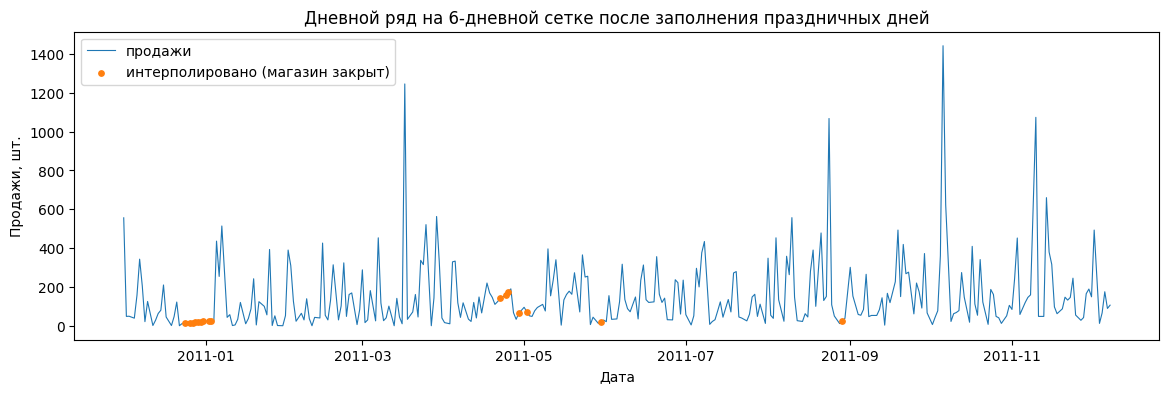

In [49]:
ax = tu.plot_series(daily_f, 'Дневной ряд на 6-дневной сетке после заполнения праздничных дней', lw=0.8, label='продажи')
filled = daily_f[daily.isna()]
ax.scatter(filled.index, filled, color='tab:orange', zorder=3, s=15, label='интерполировано (магазин закрыт)')
ax.legend()
plt.show()

### 2.3 Выбросы

Распределение дневных продаж с тяжёлым правым хвостом, а уровень ряда за год меняется примерно вдвое. Поэтому глобальное правило IQR плохо подходит: в январе 400 шт. за день — это очень много, а в ноябре почти норма. Использую **фильтр Хампеля**: скользящая медиана по 13 точкам (≈ 2 рабочие недели) и порог 3·1.4826·MAD — то есть сравниваем с локальным уровнем, а медиана и MAD сами к выбросам устойчивы. IQR посчитан для сравнения.

выбросов по Хампелю: 27 (вверх: 25 )
выбросов по глобальному IQR: 18 | верхний порог IQR: 451.125
нашёл Хампель, но не IQR: 16


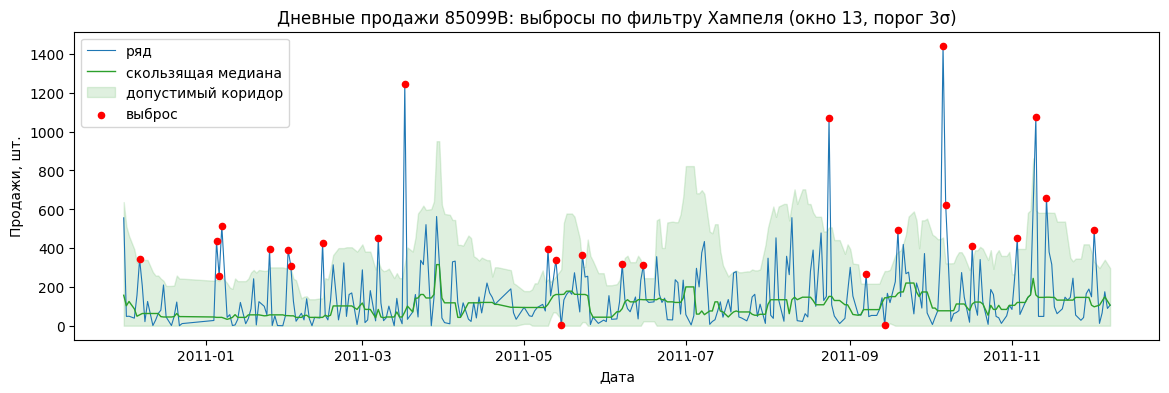

In [50]:
h = tu.hampel(daily.dropna(), window=13, n_sigmas=3)
iqr_flag, lo, hi = tu.iqr_outliers(daily.dropna())
print('выбросов по Хампелю:', h['is_outlier'].sum(),
      '(вверх:', (h['is_outlier'] & (h['value'] > h['median'])).sum(), ')')
print('выбросов по глобальному IQR:', iqr_flag.sum(), '| верхний порог IQR:', hi)
print('нашёл Хампель, но не IQR:', (h['is_outlier'] & ~iqr_flag).sum())
tu.plot_outliers(h, 'Дневные продажи 85099B: выбросы по фильтру Хампеля (окно 13, порог 3σ)')

Проверяю, откуда берутся пиковые дни: смотрю на транзакции этих дней.

In [51]:
by_day = (sales.assign(day=sales['InvoiceDate'].dt.normalize())
               .groupby('day')
               .agg(заказов=('InvoiceNo', 'nunique'), макс_заказ=('Quantity', 'max')))
out_days = h.loc[h['is_outlier'], ['value', 'median']].join(by_day)
out_days['доля_макс_заказа'] = (out_days['макс_заказ'] / out_days['value']).round(2)
out_days

,value,median,заказов,макс_заказ,доля_макс_заказа
date,,,,,
2010-12-07,343.0,56.0,10,300,0.87
2011-01-05,436.0,43.0,5,200,0.46
2011-01-06,254.0,43.0,9,100,0.39
2011-01-07,514.0,43.0,4,400,0.78
2011-01-25,393.0,56.0,12,100,0.25
2011-02-01,390.0,52.0,13,100,0.26
2011-02-02,310.0,51.0,9,100,0.32
2011-02-14,426.0,43.0,4,400,0.94
2011-03-07,453.0,84.0,12,400,0.88


In [52]:
big = sales['Quantity'] >= 100
print(f'позиций с заказом >= 100 шт.: {big.mean():.1%}')
print(f'их доля в проданном объёме: {sales.loc[big, "Quantity"].sum() / sales["Quantity"].sum():.1%}')

позиций с заказом >= 100 шт.: 9.4%
их доля в проданном объёме: 63.2%


Получается так:
- практически все «верхние» выбросы — дни, когда один клиент взял крупную партию (100–1200 шт.). Самые сильные: 17.03.2011 (заказ на 1200 шт.), 06.10.2011 и 10.11.2011 (по 1000 шт.);
- два «нижних» выброса — дни с продажей 3 шт. на фоне обычных ~150;
- IQR находит только самые большие дни в целом за год и пропускает пики в «тихие» месяцы (январь–февраль), так что Хампель тут адекватнее.

**Решение: выбросы не удаляю и не сглаживаю.** Это не ошибки данных — ошибочные (отменённые) заказы уже убраны на шаге 1.3, а оставшиеся крупные заказы реальные. Более того, заказы от 100 шт. — это меньше 10% позиций, но около 63% всего объёма: если их «срезать», от спроса останется треть. Вместо удаления дальше использую устойчивые методы (медианы, robust STL, непараметрический тест) и логарифмирование, а флаг крупного заказа можно будет потом использовать как признак в модели.

Недельный ряд:

выбросов по Хампелю (недели): 3


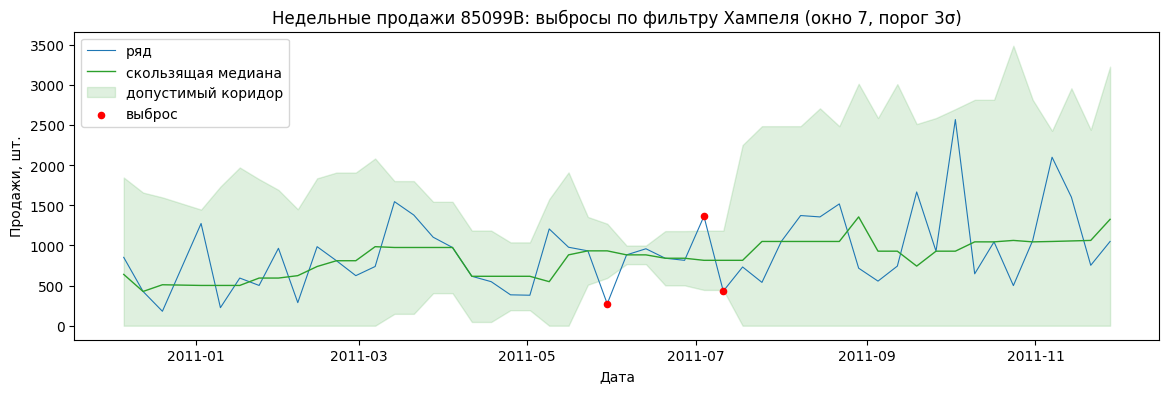

,value,median,lower,upper,is_outlier
period_start,,,,,
2011-05-30,273.0,933.0,594.9672,1271.0328,True
2011-07-04,1364.0,815.0,445.8326,1184.1674,True
2011-07-11,431.0,815.0,445.8326,1184.1674,True


In [53]:
hw = tu.hampel(weekly.dropna(), window=7, n_sigmas=3)
print('выбросов по Хампелю (недели):', hw['is_outlier'].sum())
tu.plot_outliers(hw, 'Недельные продажи 85099B: выбросы по фильтру Хампеля (окно 7, порог 3σ)')
hw[hw['is_outlier']]

На недельном уровне выбросов всего 3: неделя 04.07 вверх (за четыре дня подряд несколько заказов по 100–300 шт.) и две недели вниз — 30.05 (банковский выходной, 5 рабочих дней) и 11.07 (тихая неделя сразу после всплеска). Здесь тоже ничего не меняю: всплеск — реальные заказы, провалы объясняются календарём и обычными колебаниями.

Месячный ряд — 12 точек, формальный поиск выбросов на нём смысла не имеет. Выделяются март и август, но это те же крупные заказы (см. среднюю величину заказа в шаге 3).

## Шаг 3. Визуальный и описательный анализ

### 3.1 Описательные статистики

In [54]:
desc = pd.DataFrame({'день': tu.describe_series(daily),
                     'неделя': tu.describe_series(weekly),
                     'месяц': tu.describe_series(monthly)})
desc

,день,неделя,месяц
наблюдений,304,51,12
среднее,156.967105,913.529412,3885.666667
медиана,103.5,852.0,3651.0
ст. отклонение,184.231054,474.330912,1258.308268
минимум,0.0,180.0,2151.0
Q1,43.0,575.0,2971.75
Q3,206.25,1083.0,4974.0
максимум,1443.0,2569.0,5809.0
CV (std/mean),1.173692,0.519229,0.323833
асимметрия,3.06934,1.0838,0.196228


- *День.* Среднее 157 шт., медиана 104 — среднее заметно выше медианы, асимметрия 3.1, эксцесс 14: тяжёлый правый хвост из-за крупных заказов. CV = 1.17, т.е. разброс больше самого уровня.
- Нулевых дней всего 1.6%, ADI ≈ 1.02 — товар продаётся практически каждый рабочий день. Но CV² ненулевых продаж 1.34 > 0.49, поэтому по классификации Syntetos–Boylan спрос **erratic**: регулярный по частоте, но очень неравномерный по объёму. Для прогноза на дневном уровне это неудобный случай.
- *Неделя* и *месяц*: CV падает до 0.52 и 0.32, асимметрия почти уходит, спрос становится smooth. Агрегация хорошо гасит шум от отдельных заказов, так что неделя как шаг прогноза выглядит разумнее дня (месячных точек всего 12 — для модели мало).

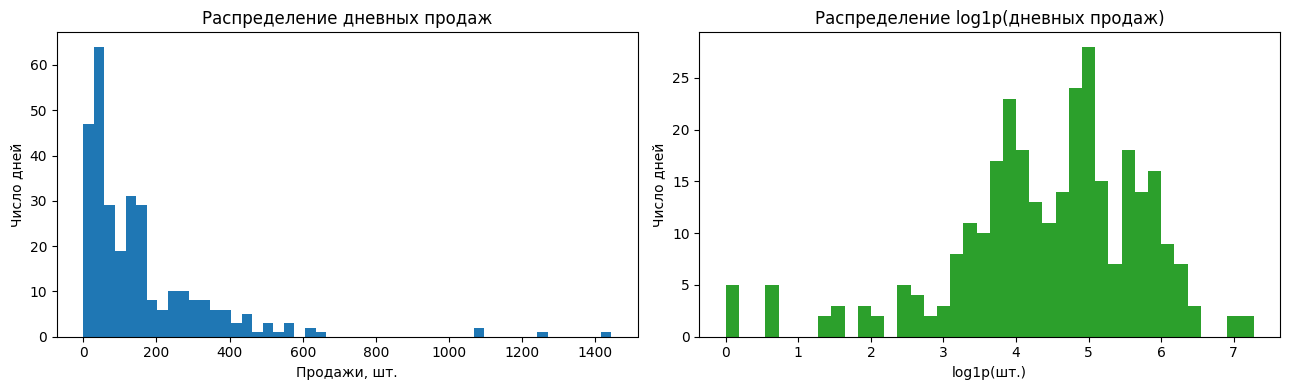

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(daily.dropna(), bins=50)
axes[0].set_title('Распределение дневных продаж')
axes[0].set_xlabel('Продажи, шт.')
axes[0].set_ylabel('Число дней')
axes[1].hist(np.log1p(daily.dropna()), bins=40, color='tab:green')
axes[1].set_title('Распределение log1p(дневных продаж)')
axes[1].set_xlabel('log1p(шт.)')
axes[1].set_ylabel('Число дней')
plt.tight_layout()
plt.show()

После `log1p` распределение становится гораздо ближе к симметричному (слева отдельно торчат нулевые и почти нулевые дни). Это аргумент в пользу логарифма при дальнейшем анализе.

### 3.2 Уровень и разброс во времени

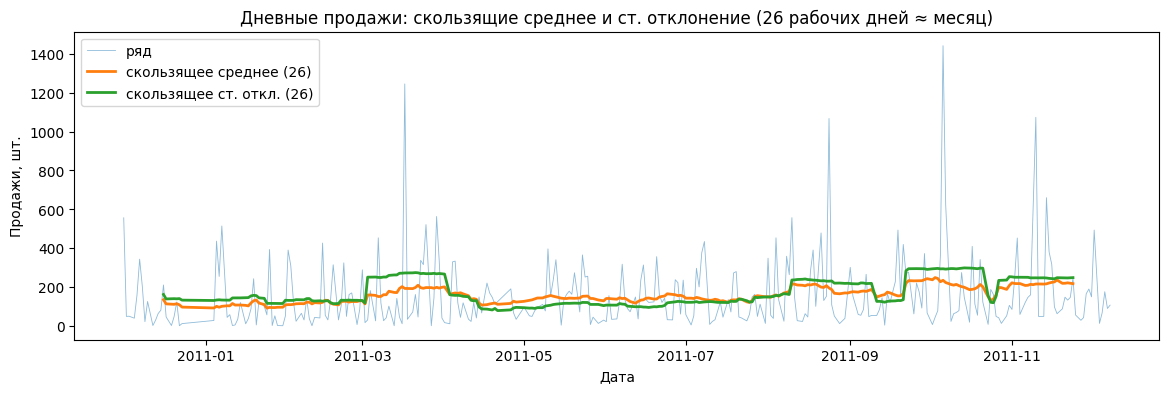

In [56]:
rm, rs = tu.plot_rolling(daily.dropna(), 26, 'Дневные продажи: скользящие среднее и ст. отклонение (26 рабочих дней ≈ месяц)')

In [57]:
tab, lev = tu.level_spread_by_month(daily[:'2011-11-30'])
print('тест Левене (равенство дисперсий по месяцам): stat = %.2f, p-value = %.3f' % (lev.statistic, lev.pvalue))
print('корреляция среднего и ст. откл. по месяцам: %.2f' % np.corrcoef(tab['среднее'], tab['ст. откл.'])[0, 1])
tab.round(1)

тест Левене (равенство дисперсий по месяцам): stat = 1.23, p-value = 0.266
корреляция среднего и ст. откл. по месяцам: 0.80


,дней,среднее,медиана,ст. откл.,CV
date,,,,,
2010-12,20,107.6,48.5,137.4,1.3
2011-01,24,110.3,51.5,148.0,1.3
2011-02,24,128.3,74.0,128.5,1.0
2011-03,27,195.6,101.0,267.3,1.4
2011-04,21,117.0,118.0,93.1,0.8
2011-05,25,144.8,110.0,115.4,0.8
2011-06,26,141.6,128.5,95.8,0.7
2011-07,26,120.3,65.0,119.5,1.0
2011-08,26,211.6,132.0,237.9,1.1


- Уровень растёт: средние дневные продажи — около 110 шт. в декабре–январе и около 220 шт. в ноябре, т.е. примерно вдвое. Рост неровный: провалы в апреле (пасхальные выходные) и в июле.
- Разброс тоже меняется: самые большие ст. отклонения в марте, августе, октябре и ноябре — как раз в месяцы с заказами на 1000+ шт. Показателен октябрь: медиана всего 77.5 при среднем 187, т.е. объём месяца сделали несколько крупных заказов. Корреляция месячного среднего и ст. отклонения 0.80 — разброс растёт вместе с уровнем, структура скорее мультипликативная.
- При этом тест Левене (вариант с медианой, устойчивый к выбросам) различие дисперсий между месяцами значимым не признаёт (p = 0.27). Дневной ряд слишком шумный, чтобы по 20–27 дням в месяце формально доказать изменение дисперсии. Итого: формально гетероскедастичность не подтверждена, но логарифм всё равно уместен — из-за сильной асимметрии и связи разброса с уровнем.

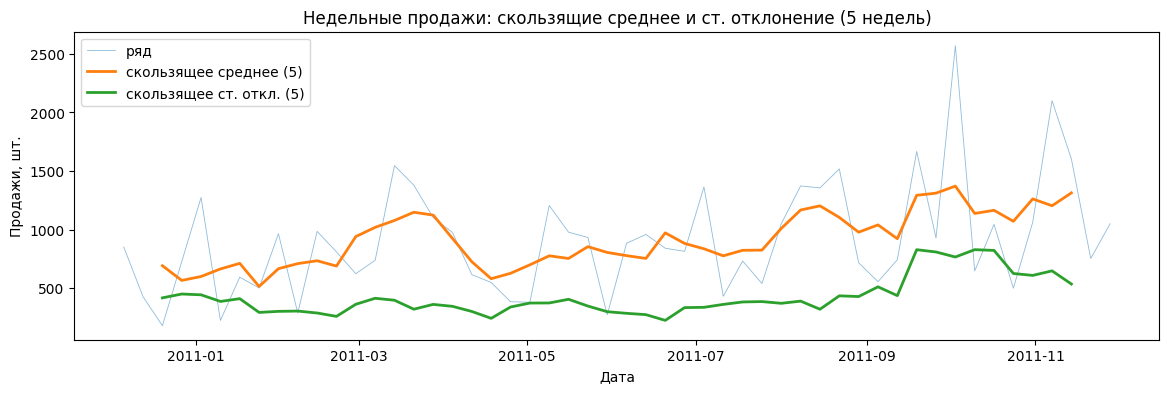

In [58]:
rmw, rsw = tu.plot_rolling(weekly_f, 5, 'Недельные продажи: скользящие среднее и ст. отклонение (5 недель)')

На недельном ряде то же самое: скользящее среднее растёт примерно с 600 до 1300 шт./нед., а скользящее ст. отклонение заметно увеличивается с середины сентября (крупные заказы в октябре и ноябре).

### 3.3 Из чего складывается рост: число заказов и их размер

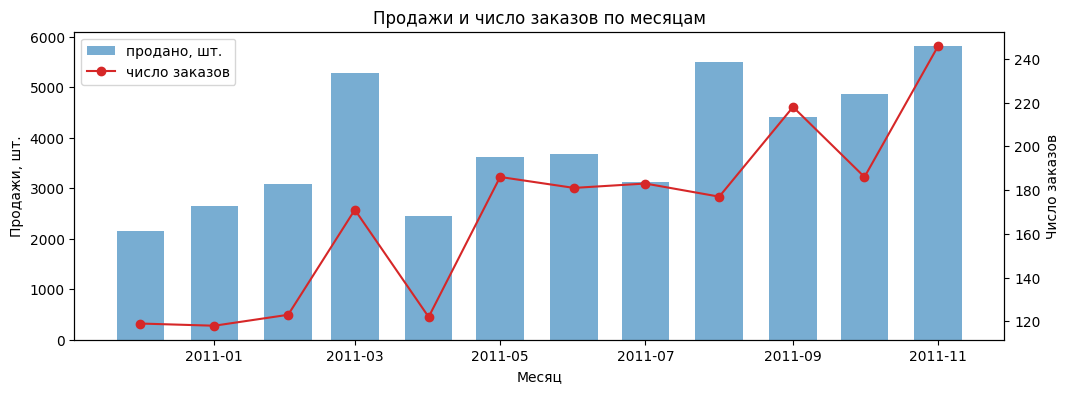

,штук,заказов,клиентов,средний_заказ
InvoiceDate,,,,
2010-12,2151,119,77,18.1
2011-01,2647,118,72,22.4
2011-02,3080,123,78,25.0
2011-03,5280,171,106,30.9
2011-04,2456,122,83,20.1
2011-05,3621,186,122,19.5
2011-06,3681,181,115,20.3
2011-07,3128,183,118,17.1
2011-08,5502,177,134,31.1


In [59]:
s_m = sales[sales['InvoiceDate'] < '2011-12-01']
by_month = s_m.groupby(s_m['InvoiceDate'].dt.to_period('M')).agg(
    штук=('Quantity', 'sum'), заказов=('InvoiceNo', 'nunique'), клиентов=('CustomerID', 'nunique'))
by_month['средний_заказ'] = (by_month['штук'] / by_month['заказов']).round(1)

fig, ax1 = plt.subplots(figsize=(12, 4))
x = by_month.index.to_timestamp()
ax1.bar(x, by_month['штук'], width=20, alpha=0.6, label='продано, шт.')
ax1.set_xlabel('Месяц')
ax1.set_ylabel('Продажи, шт.')
ax2 = ax1.twinx()
ax2.plot(x, by_month['заказов'], color='tab:red', marker='o', label='число заказов')
ax2.set_ylabel('Число заказов')
ax1.set_title('Продажи и число заказов по месяцам')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.show()
by_month

In [60]:
cust = sales.groupby('CustomerID')['Quantity'].sum().sort_values(ascending=False)
total = sales['Quantity'].sum()
print('клиентов с ID:', len(cust))
print('доля топ-10 клиентов в объёме: %.1f%%' % (100 * cust.head(10).sum() / total))
print('доля продаж без CustomerID: %.1f%%' % (100 * sales.loc[sales['CustomerID'].isna(), 'Quantity'].sum() / total))

клиентов с ID: 634
доля топ-10 клиентов в объёме: 39.0%
доля продаж без CustomerID: 4.8%


Рост объёма идёт в основном за счёт числа заказов и клиентов: заказов в месяц стало примерно вдвое больше (118 в январе → 246 в ноябре), клиентов — с 72 до 171. Средний размер заказа почти не меняется (около 20 шт.), выделяются март и август (~31 шт.) и отчасти октябрь — это месяцы с отдельными заказами на 300–1200 шт.

Покупателей 634, но продажи довольно концентрированы: топ-10 клиентов дают 39% объёма. Продажи без CustomerID — меньше 5%, так что пропуски в этом поле на ряд почти не влияют.

Единственный отрезок, который есть в данных за оба года, — начало декабря. Сравню его:

In [61]:
y2010 = daily_cal['2010-12-01':'2010-12-08']
y2011 = daily_cal['2011-12-01':'2011-12-08']
print('1-8 декабря 2010:', int(y2010.sum()), 'шт. за', y2010.count(), 'раб. дней')
print('1-8 декабря 2011:', int(y2011.sum()), 'шт. за', y2011.count(), 'раб. дней')

1-8 декабря 2010: 1397 шт. за 7 раб. дней
1-8 декабря 2011: 1090 шт. за 7 раб. дней


Интересно: в начале декабря 2011 продали меньше, чем год назад (1090 против 1397 шт. за те же 7 рабочих дней), хотя ноябрь 2011 — рекордный месяц. Значит, рост в течение года — не обязательно долгосрочный тренд: часть его может быть годовой сезонностью (оптовики закупаются осенью под Рождество, а с декабря спрос спадает). Но это сравнение одной недели, к тому же 07.12.2010 был заказ на 300 шт. Так что это наблюдение, а не доказательство.

### 3.4 Продажи по дням недели

In [62]:
wd_tab, kw = tu.weekday_profile(daily)
print('Краскел-Уоллис, все дни: H = %.1f, p-value = %.2g' % (kw.statistic, kw.pvalue))
_, kw5 = tu.weekday_profile(daily[daily.index.dayofweek != 6])
print('Краскел-Уоллис, пн-пт (без воскресенья): H = %.1f, p-value = %.2f' % (kw5.statistic, kw5.pvalue))
store_inv = df.groupby(df['InvoiceDate'].dt.normalize())['InvoiceNo'].nunique()
print('среднее число чеков в магазине за день:',
      store_inv.groupby(store_inv.index.dayofweek).mean().round().rename(dict(enumerate(tu.WEEKDAYS_RU))).to_dict())
wd_tab.round(1)

Краскел-Уоллис, все дни: H = 46.0, p-value = 9e-09
Краскел-Уоллис, пн-пт (без воскресенья): H = 4.7, p-value = 0.32
среднее число чеков в магазине за день: {'Пн': 88.0, 'Вт': 91.0, 'Ср': 91.0, 'Чт': 107.0, 'Пт': 84.0, 'Вс': 48.0}


,count,mean,median,std
Пн,47,162.5,105.0,151.0
Вт,52,172.6,149.0,123.2
Ср,53,189.5,135.0,197.9
Чт,53,214.6,134.0,286.3
Пт,49,139.9,94.0,150.1
Вс,50,56.7,30.0,80.7


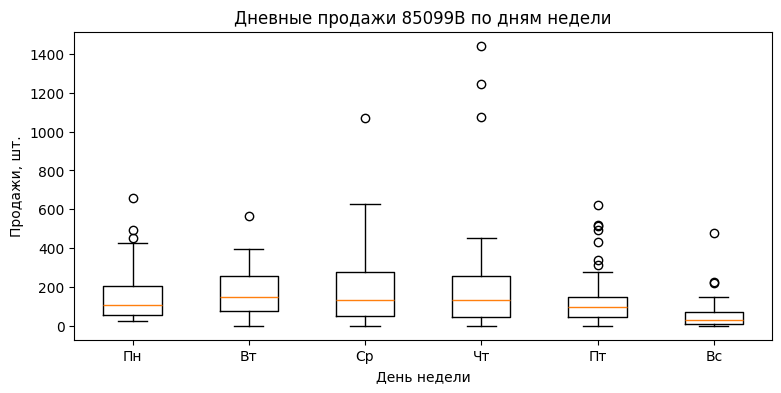

In [63]:
tu.plot_weekday_box(daily, 'Дневные продажи 85099B по дням недели')

Главная особенность — воскресенье: медиана 30 шт. против ~95–150 в будни. Это общий эффект магазина: по воскресеньям у него вообще примерно вдвое меньше чеков (48 против 84–107 в будни).

Тест Краскела–Уоллиса (непараметрический, потому что распределения скошены и с выбросами) отвергает гипотезу об одинаковых распределениях продаж по дням недели (p ≈ 1e-8). Если убрать воскресенье, различия между пн–пт уже незначимы (p = 0.32). То есть недельный цикл есть, но держится он в основном на воскресенье. Пятница по средним чуть слабее остальных будней, но статистически это не подтверждается.

### 3.5 Автокорреляция

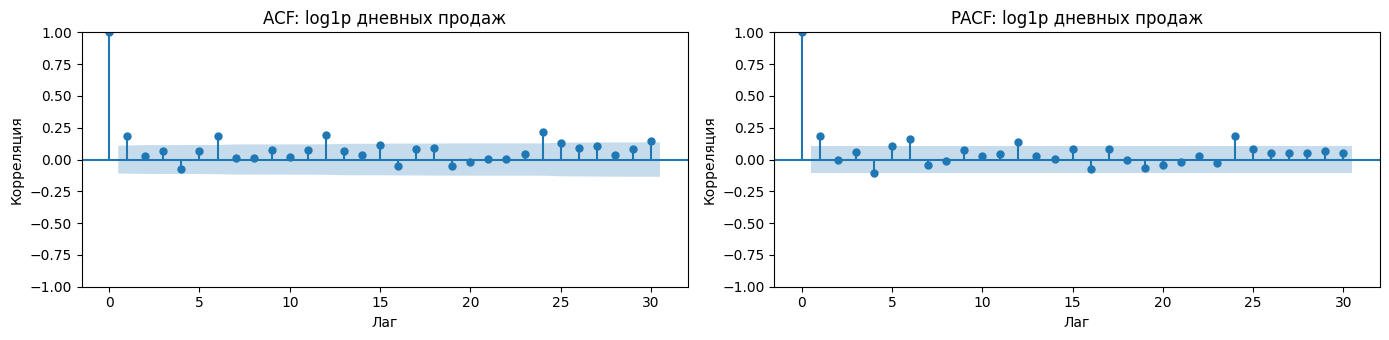

ACF дневного ряда (log1p) на лагах 1, 6, 12, 18: [0.185 0.187 0.19  0.089] | граница значимости ~ 0.11


In [64]:
tu.plot_acf_pacf(np.log1p(daily_f), lags=30, title='log1p дневных продаж')
print('ACF дневного ряда (log1p) на лагах 1, 6, 12, 18:',
      acf(np.log1p(daily_f), nlags=18)[[1, 6, 12, 18]].round(3),
      '| граница значимости ~', round(1.96 / np.sqrt(len(daily_f)), 3))

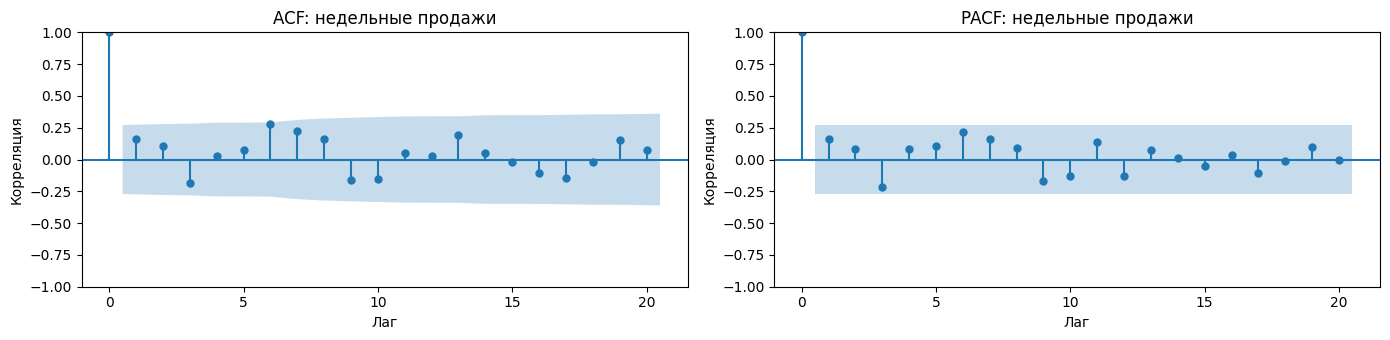

In [65]:
tu.plot_acf_pacf(weekly_f, lags=20, title='недельные продажи')

- Дневной ряд (в логарифмах): автокорреляции в целом слабые (лаг 1 ≈ 0.19), но выше границы значимости выходят лаги 6, 12 и 24 — кратные 6, т.е. неделе на нашей сетке. Это ещё одно подтверждение недельного цикла. Лаг 18 значимым не вышел, так что цикл не очень сильный.
- Недельный ряд: значимых лагов практически нет, только лаг 6 касается границы. Содержательной причины для 6-недельного цикла нет, считаю это случайностью. Медленного затухания ACF, как у случайного блуждания, тоже нет.

## Шаг 4. Декомпозиция

**Метод — STL** (Seasonal-Trend decomposition using Loess). Почему он, а не классический `seasonal_decompose`:
- в режиме `robust=True` крупные заказы уходят в остаток и не тянут за собой тренд и сезонность — для нашего ряда это главное;
- сезонная компонента может немного меняться во времени;
- не теряются точки на краях ряда.

**Период.** На дневном ряде естественный кандидат — неделя. После удаления суббот неделя = 6 наблюдений, т.е. `period=6`. Это подтверждают тест Краскела–Уоллиса и значимые ACF на лагах 6 и 12. Годовую сезонность на дневных и недельных данных выделить нельзя: данных ровно на год, а для оценки сезонной компоненты нужно минимум два полных цикла.

**Модель.** Разложение делаю для `log1p` ряда — это аддитивная модель в логарифмах, т.е. мультипликативная на исходной шкале. Причины: разброс растёт вместе с уровнем, распределение сильно скошено. `log1p`, а не `log`, — из-за нулевых дней.

**Окна сглаживания.** `trend=27` — примерно месяц рабочих дней. С окном по умолчанию (13 точек) тренд начинал повторять отдельные крупные заказы и колебался каждые две недели, а нас интересует изменение уровня в течение года. `seasonal=13` — недельный профиль сглаживается примерно по кварталу, т.е. может медленно меняться, но не подстраивается под каждую неделю.

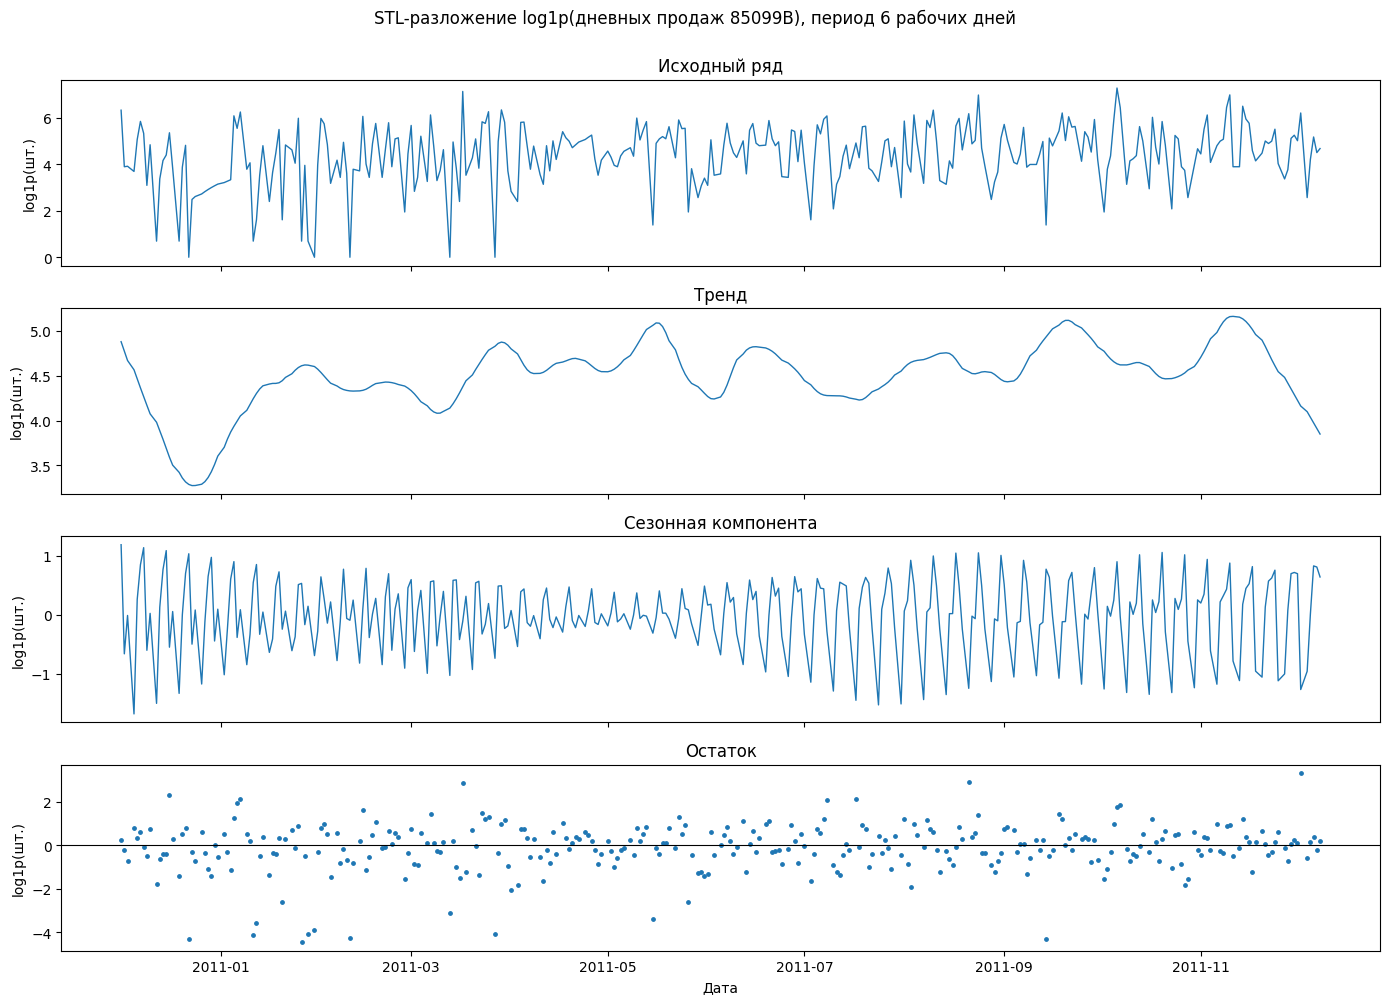

In [66]:
log_daily = np.log1p(daily_f)
stl_log = tu.stl_decompose(log_daily, period=6, seasonal=13, trend=27)
tu.plot_stl(stl_log, 'STL-разложение log1p(дневных продаж 85099B), период 6 рабочих дней', ylabel='log1p(шт.)')

In [67]:
stl_raw = tu.stl_decompose(daily_f, period=6, seasonal=13, trend=27)
pd.DataFrame({'log1p (мультипликативная)': tu.decomposition_strength(stl_log),
              'исходная шкала (аддитивная)': tu.decomposition_strength(stl_raw)}).round(3)

,log1p (мультипликативная),исходная шкала (аддитивная)
сила тренда,0.125,0.031
сила сезонности,0.191,0.124


In [68]:
prof = tu.seasonal_profile(stl_log, log_daily)
pd.DataFrame({'сезонная компонента (log)': prof.round(3),
              'множитель к тренду': np.exp(prof).round(2)})

,сезонная компонента (log),множитель к тренду
Пн,0.075,1.08
Вт,0.418,1.52
Ср,0.387,1.47
Чт,0.232,1.26
Пт,-0.126,0.88
Вс,-0.971,0.38


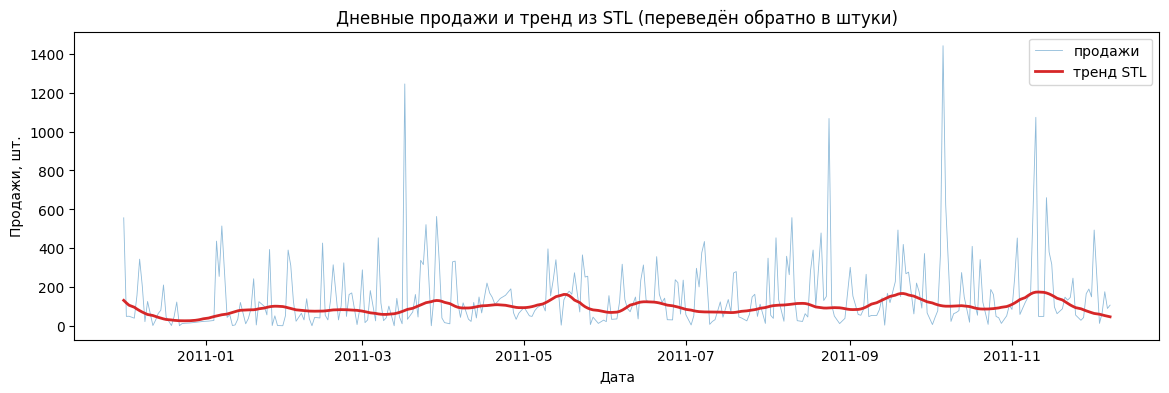

date
2010-12     51.6
2011-01     76.5
2011-02     80.1
2011-03     86.5
2011-04    101.2
2011-05    114.4
2011-06    100.6
2011-07     75.5
2011-08    101.2
2011-09    128.9
2011-10     97.8
2011-11    131.1
2011-12     56.1
Freq: M, Name: trend, dtype: float64

In [69]:
trend_units = np.expm1(stl_log.trend)
ax = tu.plot_series(daily_f, 'Дневные продажи и тренд из STL (переведён обратно в штуки)', lw=0.6, alpha=0.5, label='продажи')
ax.plot(trend_units.index, trend_units, lw=2, color='tab:red', label='тренд STL')
ax.legend()
plt.show()
trend_units.groupby(trend_units.index.to_period('M')).mean().round(1)

остаток: среднее = -0.125, ст. откл. = 1.127
точек с |остатком| > 3 robust σ: 16 | вверх: 3 | вниз: 13
из них совпадают с выбросами Хампеля: 4


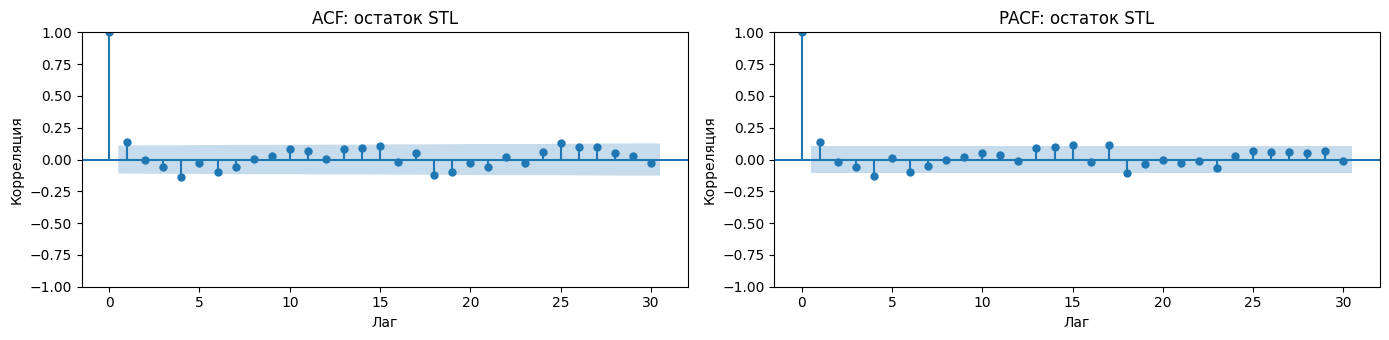

In [70]:
resid = stl_log.resid
print('остаток: среднее = %.3f, ст. откл. = %.3f' % (resid.mean(), resid.std()))
thr = 3 * 1.4826 * (resid - resid.median()).abs().median()
big_res = resid[resid.abs() > thr]
print('точек с |остатком| > 3 robust σ:', len(big_res), '| вверх:', (big_res > 0).sum(), '| вниз:', (big_res < 0).sum())
print('из них совпадают с выбросами Хампеля:', big_res.index.isin(h.index[h['is_outlier']]).sum())
tu.plot_acf_pacf(resid, lags=30, title='остаток STL')

Что получилось:
- **Тренд.** В пересчёте в штуки (тренд считался по логарифмам, поэтому это «типичный» день, ближе к медиане, чем к среднему) уровень вырос примерно с 75–80 шт. в январе–феврале до ~130 шт. в сентябре и ноябре. Рост не монотонный: проседания в июле и в октябре (в октябре объём сделали несколько огромных заказов, а обычные дни были слабее). Низкие значения в декабре 2010 и в самом конце ряда — предрождественское затишье и краевой эффект: на краях Loess-оценки ненадёжны.
- **Сезонная компонента (неделя).** Профиль устойчивый: вт и ср примерно в 1.5 раза выше тренда, чт ×1.26, пн около тренда, пт ×0.88, воскресенье ×0.38. Амплитуда немного меняется: весной цикл слабее, с июля сильнее.
- **Сила компонент** (по Wang, Smith, Hyndman): сезонность 0.19, тренд 0.13 в логарифмах, на исходной шкале ещё меньше. То есть основная часть дневной изменчивости — остаток, а не тренд и не сезонность. Для ряда, где объём делают отдельные крупные заказы, это ожидаемо.
- **Остаток** колеблется около нуля, в его ACF сезонных лагов (6, 12) больше нет — недельную структуру STL забрал; остались небольшие выходы за границу на лагах 1 и 4. Самые большие остатки в логарифмах — дни с почти нулевыми продажами (13 из 16 отклонений больше 3σ направлены вниз), а крупные заказы в логарифмах выглядят скромнее. С выбросами Хампеля (они искались на исходной шкале и почти все вверх) совпадают только 4 дня: логарифм и исходная шкала подсвечивают разные аномалии.

### Недельный и месячный ряды

На недельном ряде годовой период (52 недели) — это один цикл, оценить его нельзя, а других естественных периодов у недельных продаж нет (в ACF устойчивых сезонных пиков нет). Поэтому недельный ряд раскладываю только на тренд и остаток: линейный тренд (МНК) и скользящее среднее за 5 недель для сравнения.

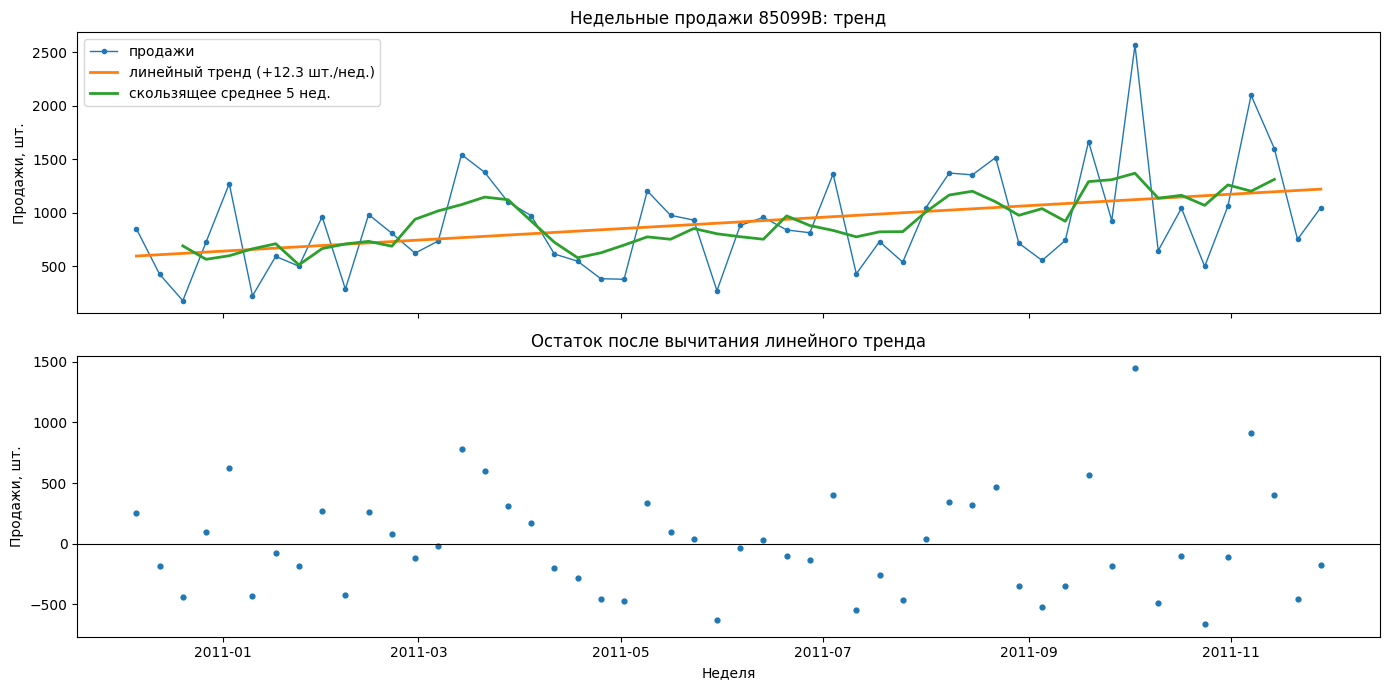

тренд: 597 шт./нед. в начале -> 1222 шт./нед. в конце


In [71]:
t = np.arange(len(weekly_f))
b, a = np.polyfit(t, weekly_f.values, 1)
lin_trend = pd.Series(a + b * t, index=weekly_f.index)
ma5 = weekly_f.rolling(5, center=True).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(weekly_f.index, weekly_f, marker='o', ms=3, lw=1, label='продажи')
axes[0].plot(lin_trend.index, lin_trend, lw=2, label=f'линейный тренд ({b:+.1f} шт./нед.)')
axes[0].plot(ma5.index, ma5, lw=2, label='скользящее среднее 5 нед.')
axes[0].set_title('Недельные продажи 85099B: тренд')
axes[0].set_ylabel('Продажи, шт.')
axes[0].legend()
axes[1].scatter(weekly_f.index, weekly_f - lin_trend, s=12)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_title('Остаток после вычитания линейного тренда')
axes[1].set_xlabel('Неделя')
axes[1].set_ylabel('Продажи, шт.')
plt.tight_layout()
plt.show()
print(f'тренд: {lin_trend.iloc[0]:.0f} шт./нед. в начале -> {lin_trend.iloc[-1]:.0f} шт./нед. в конце')

Линейный тренд: +12.3 шт. в неделю, т.е. примерно с 600 до 1220 шт./нед. за год — рост вдвое. Скользящее среднее показывает, что рост неравномерный: подъём в марте, спад в апреле–мае, затем рост с августа. Остаток после вычитания тренда без явной структуры, но к осени его разброс больше.

### Вывод о сезонности

- **Недельная сезонность есть**: период 7 календарных дней (6 рабочих). Подтверждается тремя способами: тест Краскела–Уоллиса по дням недели (p ≈ 1e-8), значимые ACF на лагах 6, 12, 24 и устойчивый сезонный профиль STL. Но по силе она слабая (F_s ≈ 0.19) и держится в основном на воскресенье — оно примерно в 2.5 раза ниже тренда.
- **Годовую сезонность установить нельзя.** Данных 13 месяцев, т.е. один цикл. Рост продаж к осени виден, но по одному году нельзя отличить тренд от годового цикла. Сравнение начала декабря 2010 и 2011 скорее намекает на сезонный характер осеннего пика, но это одна неделя.
- На недельном и месячном рядах других сезонных периодов не видно (в ACF недельного ряда нет значимых сезонных лагов).

## Шаг 5. Стационарность

Использую два теста с противоположными нулевыми гипотезами, потому что по отдельности каждый может ошибаться:
- **ADF** (расширенный тест Дики–Фуллера): H0 — в ряде есть единичный корень, ряд нестационарен. p < 0.05 → отвергаем H0 → признак стационарности.
- **KPSS**: H0 — ряд стационарен (вокруг константы при `regression='c'` или вокруг линейного тренда при `'ct'`). p < 0.05 → признак нестационарности. В statsmodels p-value KPSS обрезано диапазоном [0.01; 0.1], поэтому 0.1 значит «≥ 0.1».

Проверяю дневной и недельный ряды. Месячный ряд не тестирую: 12 точек — у тестов практически нет мощности, результат был бы случайным.

### 5.1 Исходные ряды

In [72]:
st_c = tu.stationarity_report({'день, исходный': daily_f, 'неделя, исходный': weekly_f}, regression='c')
st_c

,n,ADF stat,ADF p-value,ADF lags,ADF crit 5%,KPSS stat,KPSS p-value,KPSS crit 5%,вывод
"день, исходный",320,-5.175176,0.00001,8,-2.870879,0.71153,0.012497,0.463,"противоречие: ADF - стац., KPSS - нет"
"неделя, исходный",52,-1.170327,0.686228,10,-2.935135,0.643821,0.018653,0.463,нестационарен


- **Дневной ряд:** ADF уверенно отвергает единичный корень (p ≈ 1e-5), а KPSS отвергает стационарность вокруг константы (p ≈ 0.012). Такое противоречие типично для ряда, у которого нет случайного блуждания, но среднее со временем смещается (тренд).
- **Недельный ряд:** оба теста сходятся — нестационарен (ADF p = 0.69, KPSS p = 0.019). Правда, ADF выбрал 10 лагов на 52 точках, мощность у него тут небольшая.

Проверяю гипотезу про тренд: те же тесты, но с линейным трендом в регрессии (`regression='ct'`).

In [73]:
st_ct = tu.stationarity_report({'день, исходный': daily_f, 'неделя, исходный': weekly_f}, regression='ct')
st_ct

,n,ADF stat,ADF p-value,ADF lags,ADF crit 5%,KPSS stat,KPSS p-value,KPSS crit 5%,вывод
"день, исходный",320,-9.874288,0.0,3,-3.424476,0.03429,0.1,0.146,стационарен
"неделя, исходный",52,-5.90208,0.000004,2,-3.504239,0.039862,0.1,0.146,стационарен


С учётом линейного тренда оба ряда по обоим тестам стационарны: ADF отвергает единичный корень (p < 0.001), KPSS не отвергает стационарность вокруг тренда (p ≥ 0.1). Значит, нестационарность исходных рядов — это **детерминированный тренд** (рост в течение года), а не случайное блуждание. Ряды тренд-стационарны, и для приведения к стационарности достаточно убрать тренд.

### 5.2 Преобразования

1. `log1p` — уменьшает асимметрию и выравнивает разброс (он растёт вместе с уровнем).
2. Убрать тренд — двумя способами, чтобы сравнить:
   - первая разность (дифференцирование);
   - вычитание линейного тренда (раз тесты с `'ct'` показывают, что ряд стационарен вокруг тренда).

In [74]:
transformed = {
    'день: log1p + diff': tu.make_stationary(daily_f, log=True, diff=1),
    'день: log1p - лин. тренд': tu.detrend_linear(np.log1p(daily_f)),
    'неделя: log1p + diff': tu.make_stationary(weekly_f, log=True, diff=1),
    'неделя: log1p - лин. тренд': tu.detrend_linear(np.log1p(weekly_f)),
}
st_tr = tu.stationarity_report(transformed, regression='c')
st_tr

,n,ADF stat,ADF p-value,ADF lags,ADF crit 5%,KPSS stat,KPSS p-value,KPSS crit 5%,вывод
день: log1p + diff,319,-7.52492,0.0,15,-2.871127,0.057864,0.1,0.463,стационарен
день: log1p - лин. тренд,320,-10.258427,0.0,3,-2.87073,0.107063,0.1,0.463,стационарен
неделя: log1p + diff,51,-6.205106,0.0,5,-2.928299,0.153238,0.1,0.463,стационарен
неделя: log1p - лин. тренд,52,-5.509705,0.000002,2,-2.922629,0.048903,0.1,0.463,стационарен


In [75]:
for name, x in transformed.items():
    print(f'{name:28s} ACF(1) = {acf(x, nlags=1)[1]:+.2f}')

день: log1p + diff           ACF(1) = -0.40
день: log1p - лин. тренд     ACF(1) = +0.13
неделя: log1p + diff         ACF(1) = -0.44
неделя: log1p - лин. тренд   ACF(1) = -0.02


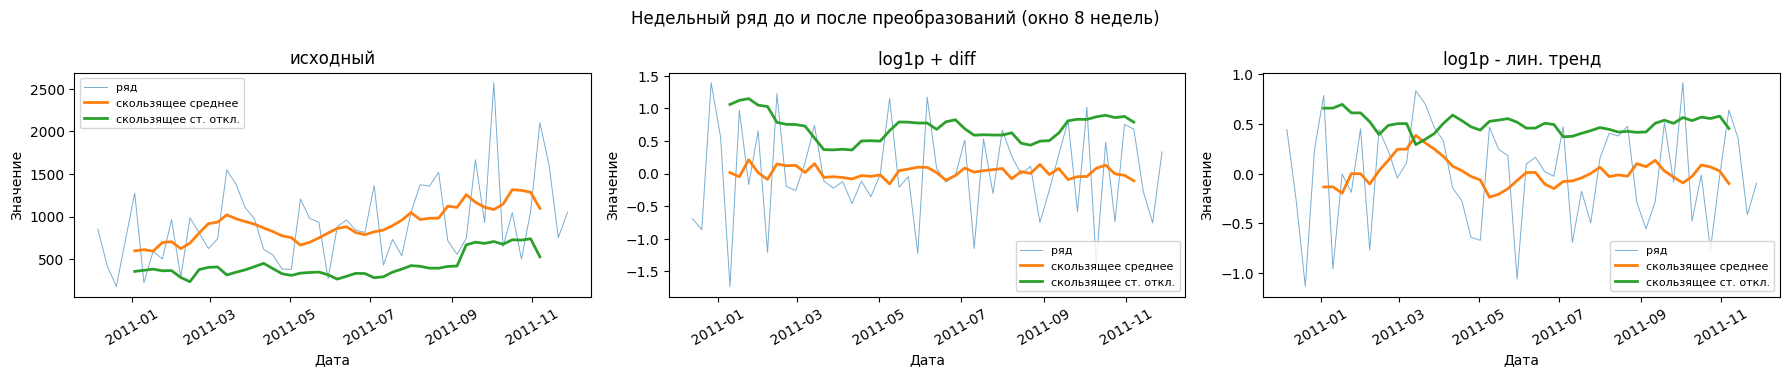

In [76]:
tu.compare_rolling({'исходный': weekly_f,
                    'log1p + diff': transformed['неделя: log1p + diff'],
                    'log1p - лин. тренд': transformed['неделя: log1p - лин. тренд']},
                   window=8, title='Недельный ряд до и после преобразований (окно 8 недель)', ylabel='Значение')

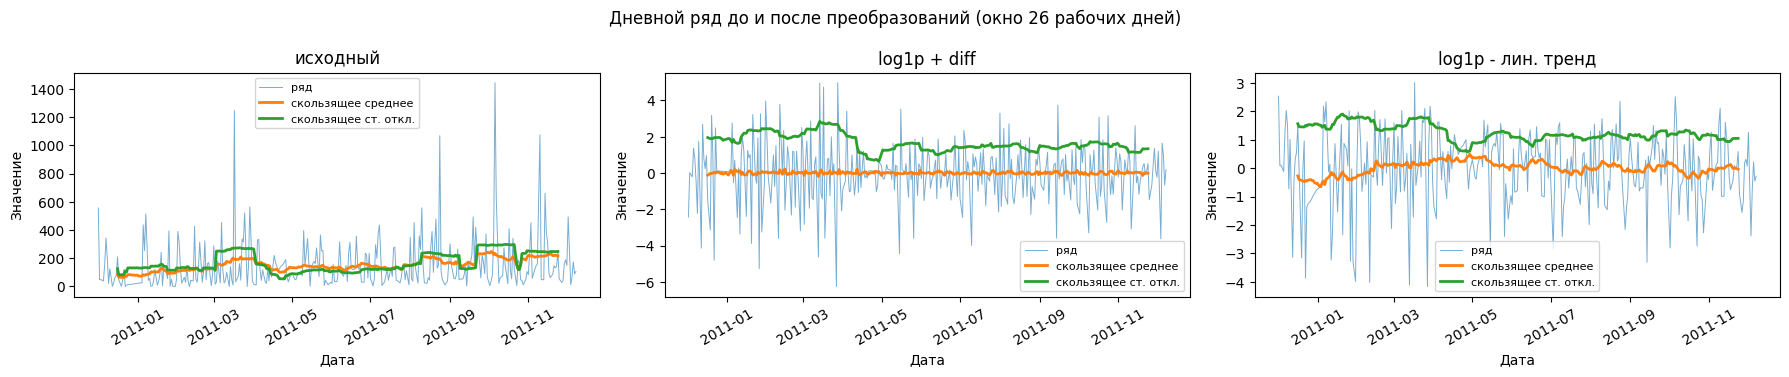

In [77]:
tu.compare_rolling({'исходный': daily_f,
                    'log1p + diff': transformed['день: log1p + diff'],
                    'log1p - лин. тренд': transformed['день: log1p - лин. тренд']},
                   window=26, title='Дневной ряд до и после преобразований (окно 26 рабочих дней)', ylabel='Значение')

In [78]:
summary = pd.concat([st_c, st_tr])[['n', 'ADF p-value', 'KPSS p-value', 'вывод']]
summary

,n,ADF p-value,KPSS p-value,вывод
"день, исходный",320,0.00001,0.012497,"противоречие: ADF - стац., KPSS - нет"
"неделя, исходный",52,0.686228,0.018653,нестационарен
день: log1p + diff,319,0.0,0.1,стационарен
день: log1p - лин. тренд,320,0.0,0.1,стационарен
неделя: log1p + diff,51,0.0,0.1,стационарен
неделя: log1p - лин. тренд,52,0.000002,0.1,стационарен


- После любого из двух преобразований оба теста согласны: ряды стационарны (ADF p < 0.001, KPSS p ≥ 0.1). На графиках скользящее среднее после преобразования держится около нуля, без тренда. У дневного ряда в логарифмах разброс зимой немного выше, чем летом и осенью (в логарифмах сильнее «торчат» почти нулевые дни, а зимой их больше), но тренда в скользящем ст. отклонении нет.
- Но у разностей ACF(1) = −0.40 (день) и −0.44 (неделя) — близко к −0.5. Это классический признак передифференцирования: если ряд стационарен вокруг тренда, разность добавляет в него искусственную отрицательную автокорреляцию (необратимую MA-часть). После вычитания линейного тренда такого эффекта нет (ACF(1) = 0.13 и −0.02).
- Поэтому для этих данных предпочтительное преобразование — **log1p + удаление тренда**. Дифференцирование тоже даёт стационарный ряд (например, для ARIMA с d=1), но модели тогда придётся компенсировать лишнюю MA-составляющую.
- Сезонное дифференцирование (лаг 6) для дневного ряда не делаю: недельный цикл слабый и стабильный, тестам стационарности он не мешает, и его проще учесть признаками дня недели.
- Оговорка: тренд оценён по одному году. Если осенний рост — годовая сезонность, то экстраполировать линейный тренд далеко вперёд опасно.

## Шаг 6. Функции

Все методы лежат в `ts_utils.py`, в ноутбуке только вызовы:

| этап | функции |
|---|---|
| загрузка и очистка | `load_data`, `get_trading_days`, `prepare_product`, `drop_cancelled_orders` |
| формирование рядов | `make_daily`, `aggregate`, `to_six_day_grid`, `fill_gaps` |
| пропуски и выбросы | `missing_report`, `hampel`, `iqr_outliers`, `plot_outliers` |
| описательный анализ | `describe_series`, `level_spread_by_month`, `weekday_profile`, `plot_series`, `plot_rolling`, `plot_weekday_box`, `plot_acf_pacf` |
| декомпозиция | `stl_decompose`, `decomposition_strength`, `seasonal_profile`, `plot_stl` |
| стационарность | `adf_test`, `kpss_test`, `stationarity_report`, `make_stationary`, `detrend_linear`, `compare_rolling` |

Функции не завязаны на конкретный товар — для другого товара достаточно поменять `STOCK_CODE` в начале ноутбука (праздники и выводы, конечно, придётся проверить заново). Случайности в расчётах нет, ноутбук воспроизводится при запуске сверху вниз.

## Шаг 7. Выводы

**Товар и показатель.** 85099B JUMBO BAG RED RETROSPOT, количество проданных штук, 01.12.2010–08.12.2011 (09.12 — неполный день, исключён).

**Качество данных.**
- Удалены 6 отменённых заказов (741 шт.) и 3 служебные строки с нулевой ценой; частичные возвраты (~370 шт.) не вычитались.
- Потерянных данных нет: все 69 дней без наблюдений — субботы (магазин не работает) и 16 праздников, включая закрытие 24.12–03.01. Нулей на рабочих днях всего 5 — это реальные нулевые продажи.
- Дневной ряд переведён на 6-дневную сетку, праздники для STL и тестов заполнены линейной интерполяцией. Неполные первая и последняя недели и декабрь 2011 исключены, закрытая неделя 27.12–02.01 интерполирована.
- Выбросы (фильтр Хампеля): 27 дней, почти все — реальные крупные оптовые заказы (до 1200 шт.). Не удалялись: заказы от 100 шт. дают ~63% объёма.

**Закономерности.**
- На дневном уровне спрос erratic: продажи почти каждый день, но CV ≈ 1.2, асимметрия 3.1. Недельный и месячный ряды гораздо ровнее (CV 0.52 и 0.32).
- За год продажи выросли примерно вдвое (линейный тренд недельного ряда ~600 → ~1220 шт./нед.), в основном за счёт числа заказов и клиентов, а не размера заказа.
- Разброс растёт вместе с уровнем (корреляция 0.8), хотя тест Левене это формально не подтверждает.

**Сезонность.** Недельная (7 дней / 6 рабочих) — есть, статистически значима, но слабая (F_s ≈ 0.19) и связана в основном с низкими продажами по воскресеньям. Годовую установить нельзя — в данных один цикл.

**Стационарность.** Дневной ряд: ADF — стационарен, KPSS — нет; недельный — нестационарен по обоим тестам. С трендом в регрессии оба стационарны, т.е. ряды тренд-стационарны. После log1p и удаления линейного тренда (или взятия разности) оба теста подтверждают стационарность; удаление тренда предпочтительнее, так как разность даёт признаки передифференцирования (ACF(1) ≈ −0.4).

**Для прогнозирования.** Работать с log1p, тренд моделировать явно, в дневную модель добавить день недели и флаги праздников и крупных заказов. Недельная агрегация заметно устойчивее дневной.